# 2 · Fitting the US Treasury yield curve: Nelson-Siegel and Svensson
Constant-maturity Treasury yields from FRED (1 month to 30 years, 11 maturities).

$$y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}+\beta_2\Big(\frac{1-e^{-\tau/\lambda}}{\tau/\lambda}-e^{-\tau/\lambda}\Big)\;\big[+\beta_3(\cdots\lambda_2)\big]$$

$\beta_0$ is the long-run level, $-\beta_1$ the slope and $\beta_2$ the curvature. Svensson adds a second hump with its own decay $\lambda_2$.

**Estimation.** For a fixed $\lambda$ the model is linear in the betas, so `fineco.yieldcurve` profiles out the betas by least squares and searches only over $\lambda$ (with multi-start for Svensson). That removes the local-minimum problem of fitting all parameters jointly.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data
from fineco import yieldcurve as yc

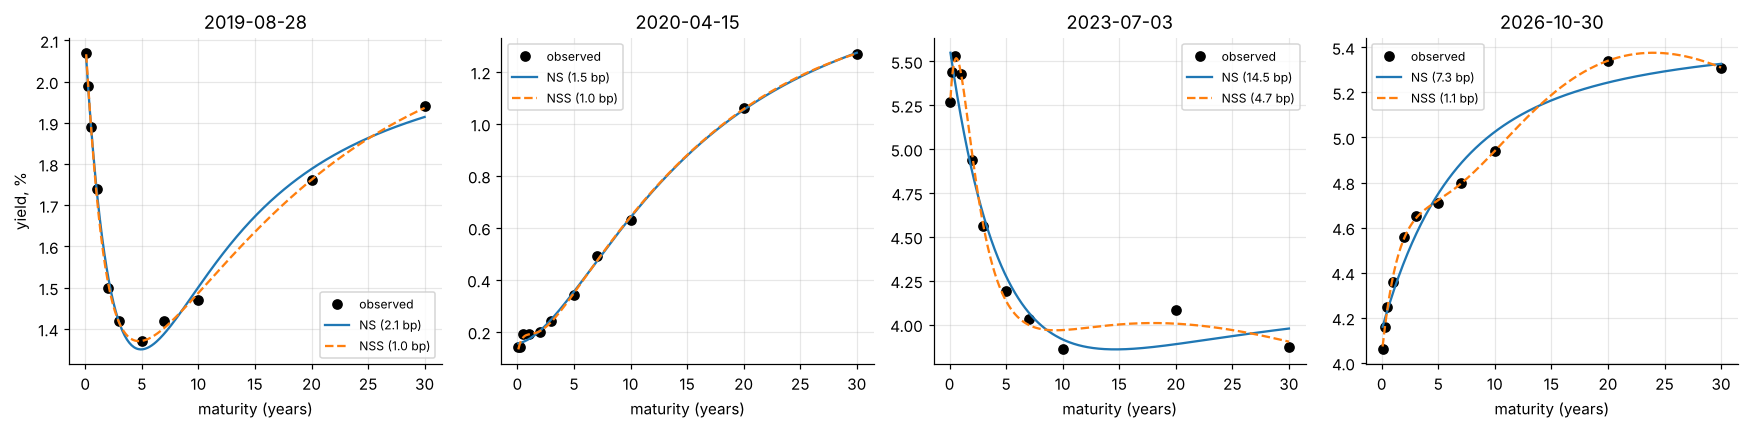

,NS level,NS slope(-b1),NS curvature,NS lambda,NS RMSE bp,NSS RMSE bp
date,,,,,,
2019-08-28,2.172,0.078,-2.631e+00,2.854,2.108,0.986
2020-04-15,1.769,1.614,-1.550e+00,4.735,1.520,1.019
2023-07-03,4.251,-1.335,-3.054e+00,4.906,14.499,4.719
2026-10-30,5.495,1.349,-8.668e-08,3.741,7.286,1.106


In [2]:
Y = data.load_yields()
tau = Y.columns.values.astype(float)
dates = [d for d in ["2019-08-28", "2020-04-15", "2023-07-03", Y.index[-1].strftime("%Y-%m-%d")]]
grid = np.linspace(1/12, 30, 300)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
rows = []
for ax, d in zip(axes, dates):
    y = Y.loc[d]
    ns, sv = yc.fit_nelson_siegel(tau, y.values), yc.fit_svensson(tau, y.values)
    ax.plot(tau, y.values, "o", c="k", label="observed")
    ax.plot(grid, ns(grid), label=f"NS ({ns.rmse_bp:.1f} bp)")
    ax.plot(grid, sv(grid), "--", label=f"NSS ({sv.rmse_bp:.1f} bp)")
    ax.set_title(d); ax.set_xlabel("maturity (years)"); ax.legend(fontsize=8)
    rows.append({"date": d, "NS level": ns.betas[0], "NS slope(-b1)": -ns.betas[1], "NS curvature": ns.betas[2],
                 "NS lambda": ns.lams[0], "NS RMSE bp": ns.rmse_bp, "NSS RMSE bp": sv.rmse_bp})
axes[0].set_ylabel("yield, %")
plt.tight_layout(); plt.savefig(FIG / "02_curve_fits.png", bbox_inches="tight"); plt.show()
pd.DataFrame(rows).set_index("date")

## Dynamic Nelson-Siegel (Diebold-Li)
Fitting every day with one common $\lambda$ turns the curve into three factor time series. The level, slope and curvature factors line up closely with simple observable proxies, which is a useful sanity check.

common lambda = 2.04 years | median daily fit RMSE = 6.2 bp
corr(level, 10y)            = 0.961
corr(-slope, 10y-3m)        = 0.97
corr(curvature, butterfly)  = 0.94


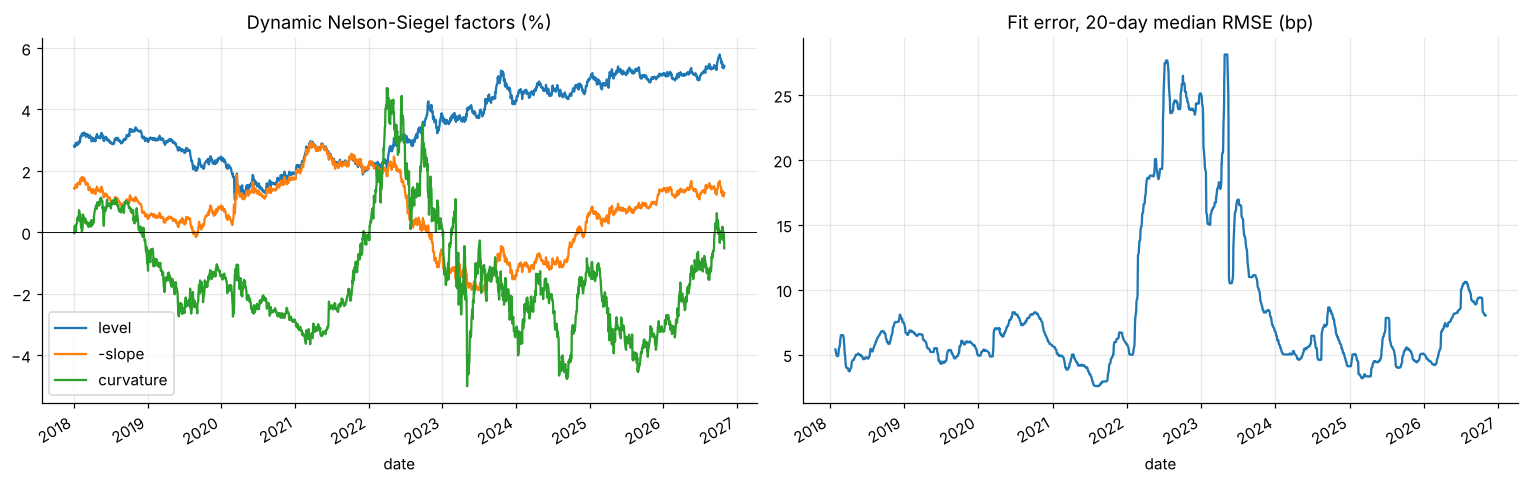

In [3]:
F, lam = yc.fit_panel(Y)
print(f"common lambda = {lam:.2f} years | median daily fit RMSE = {F.rmse_bp.median():.1f} bp")
proxy = pd.DataFrame({"level proxy (10y)": Y[10], "slope proxy (10y-3m)": Y[10] - Y[0.25],
                      "curvature proxy (2*2y-3m-10y)": 2 * Y[2] - Y[0.25] - Y[10]})
print("corr(level, 10y)            =", round(F.level.corr(proxy.iloc[:, 0]), 3))
print("corr(-slope, 10y-3m)        =", round((-F.slope).corr(proxy.iloc[:, 1]), 3))
print("corr(curvature, butterfly)  =", round(F.curvature.corr(proxy.iloc[:, 2]), 3))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
F[["level"]].assign(**{"-slope": -F.slope, "curvature": F.curvature}).plot(ax=axes[0], title="Dynamic Nelson-Siegel factors (%)")
axes[0].axhline(0, c="k", lw=.6)
F.rmse_bp.rolling(20).median().plot(ax=axes[1], title="Fit error, 20-day median RMSE (bp)")
plt.tight_layout(); plt.savefig(FIG / "02_dns_factors.png", bbox_inches="tight"); plt.show()

In [4]:
inv = (Y[10] - Y[0.25]) < 0
print(f"10y-3m inverted on {inv.mean():.0%} of days; longest inversion run starts",
      inv.astype(int).diff().eq(1).pipe(lambda s: s[s].index[0]).date())

10y-3m inverted on 33% of days; longest inversion run starts 2019-03-22


## Findings
* Svensson fits every date tested to about 1 bp RMSE except the deeply inverted July 2023 curve (4.7 bp). Nelson-Siegel is within about 2 bp on the 2019 and 2020 curves but misses the 2023 inversion by 14.5 bp and the current humped curve by 7.3 bp, because a single hump cannot capture a short-end peak *and* a 20-year bulge.
* With a common decay parameter (λ = 2.04 years) the dynamic Nelson-Siegel factors track their observable proxies closely: level vs 10-year yield 0.96, slope vs 10y-3m spread 0.97, curvature vs the 2-year butterfly 0.94.
* The 10y-3m spread was inverted on 33% of the days in the sample. Fit errors spike during 2022-23, when hiking cycles distorted the front end of the curve.